# Olist — анализ товаров

Четыре вопроса о продаваемости товаров, связи цены и спроса, структуре выручки по категориям и дорогих нишевых товарах.

**Данные:** слой Gold, витрина `gold_product_metrics` (одна строка на товар, проданный хотя бы раз) и факты продаж.

**Определения:**

| Понятие | Определение |
|---|---|
| Продажи товара (штуки) | число позиций в валидных заказах; в Olist количество — это повторяющиеся строки, отдельной колонки нет |
| Заказы товара | число разных валидных заказов с этим товаром |
| Выручка товара | сумма `price`, без доставки |

У товаров нет названий: в датасете только хэш `product_id` и категория. Поэтому товары показаны как «категория · первые символы id».

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics.db import q
from src.analytics import style as st

st.apply_style()
pd.set_option("display.float_format", lambda v: st.num(v, 2))
pd.set_option("display.max_columns", 30)

## Самые продаваемые товары

**Вопрос:** какие товары продаются лучше всего и насколько продажи сосредоточены в немногих товарах?
**Метрики:** продажи в штуках, заказы, выручка по товару; распределение товаров по числу продаж.

In [2]:
products = q("""
    select product_key, category_en, units, orders, revenue, avg_price, avg_review_score, revenue_rank, units_rank
    from gold_product_metrics
""")
products["label"] = products.category_en + " · " + products.product_key.str[:6]
top_units = products.sort_values("units", ascending=False).head(15)
top_units[["label", "units", "orders", "revenue", "avg_price", "avg_review_score"]]

,label,units,orders,revenue,avg_price,avg_review_score
0,furniture_decor · aca2eb,527,431,"37 608,90","71,36","4,10"
1,bed_bath_table · 99a478,487,466,"42 938,66","88,17","3,91"
2,garden_tools · 422879,484,352,"26 577,22","54,91","4,14"
3,garden_tools · 389d11,391,310,"21 390,69","54,71","4,19"
4,garden_tools · 368c6c,388,291,"21 056,80","54,27","4,13"
5,garden_tools · 53759a,373,287,"20 387,20","54,66","3,98"
6,computers_accessories · d1c427,341,321,"46 916,51","137,59","4,25"
7,watches_gifts · 53b36d,323,306,"37 683,42","116,67","4,23"
8,health_beauty · 154e7e,281,269,"6 325,19","22,51","4,31"
9,computers_accessories · 3dd2a1,274,255,"41 082,60","149,94","4,30"


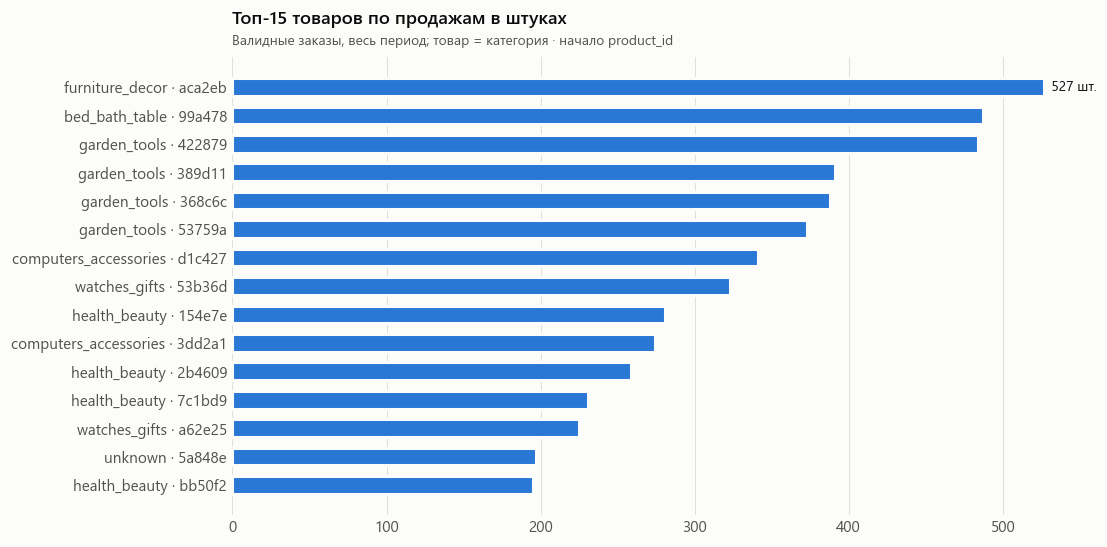

In [3]:
fig, ax = plt.subplots(figsize=(10, 5.4))
st.hbar(ax, top_units.label, top_units.units, fmt=lambda v: f"{st.num(v)} шт.")
st.count_axis(ax, "x")
st.titles(ax, "Топ-15 товаров по продажам в штуках", "Валидные заказы, весь период; товар = категория · начало product_id")
st.save(fig, "olist_products_01_top_products_units")
plt.show()

In [4]:
buckets = q("""
    select case when units = 1 then '1'
                when units <= 5 then '2–5'
                when units <= 20 then '6–20'
                when units <= 100 then '21–100'
                else 'больше 100' end as units_bucket,
           min(units)    as sort_key,
           count(*)      as products,
           sum(revenue)  as revenue
    from gold_product_metrics
    group by 1
    order by sort_key
""")
buckets["product_share"] = buckets.products / buckets.products.sum()
buckets["revenue_share"] = buckets.revenue / buckets.revenue.sum()
st.as_pct(buckets.drop(columns="sort_key"), ["product_share", "revenue_share"])

,units_bucket,products,revenue,product_share,revenue_share
0,1,17983,"2 893 390,94","54,9%","21,4%"
1,2–5,10931,"3 966 983,29","33,4%","29,4%"
2,6–20,3156,"3 416 260,16","9,6%","25,3%"
3,21–100,602,"2 187 557,30","1,8%","16,2%"
4,больше 100,57,"1 030 209,05","0,2%","7,6%"


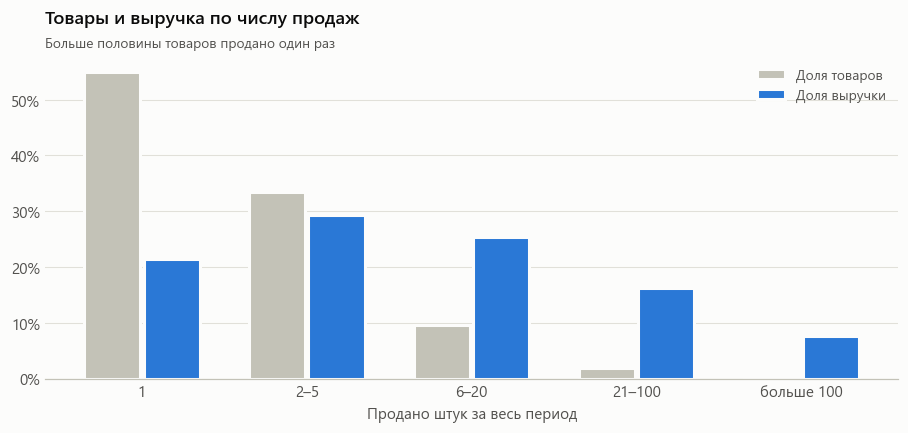

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(buckets))
ax.bar(x - 0.18, buckets.product_share, width=0.34, color=st.CONTEXT, label="Доля товаров", edgecolor=st.SURFACE, linewidth=2)
ax.bar(x + 0.18, buckets.revenue_share, width=0.34, color=st.BLUE, label="Доля выручки", edgecolor=st.SURFACE, linewidth=2)
ax.set_xticks(x, buckets.units_bucket)
ax.set_xlabel("Продано штук за весь период")
st.percent_axis(ax)
ax.legend(loc="upper right")
st.titles(ax, "Товары и выручка по числу продаж", "Больше половины товаров продано один раз")
st.save(fig, "olist_products_02_long_tail")
plt.show()

In [6]:
top100 = products.loc[products.revenue_rank <= 100, "revenue"].sum() / products.revenue.sum()
pd.DataFrame({"товаров": [len(products)], "медиана продаж, шт.": [products.units.median()],
              "доля выручки топ-100 товаров": [st.pct(top100, 1)]})

,товаров,"медиана продаж, шт.",доля выручки топ-100 товаров
0,32729,"1,00","13,5%"


**Формула**

$$\text{доля}_{u=1} = \frac{\left|\{\, j : u_j = 1 \,\}\right|}{J}, \qquad \text{доля}_{\text{топ-100}} = \frac{\sum_{j \in \text{топ-100}} R_j}{\sum_{j=1}^{J} R_j}$$

где $u_j$ — продажи товара $j$ в штуках, $R_j$ — его выручка, $J$ — число проданных товаров.

**Пример расчёта**

$$\text{доля}_{u=1} = \frac{17\,983}{32\,729} \approx 0{,}549, \qquad \text{доля}_{\text{топ-100}} = \frac{1\,828\,460{,}83}{13\,494\,400{,}74} \approx 0{,}136$$

**Вывод.**
- Ассортимент — **длинный хвост**: из 32 729 проданных товаров **55% проданы ровно один раз**, медиана — 1 штука.
  Эти товары всё же дают 21% выручки.
- Хиты редки: только 57 товаров продано больше 100 раз (7,6% выручки), а **топ-100 товаров по выручке дают 13,5%**.
  Выручка Olist не держится на нескольких бестселлерах.
- Среди лидеров продаж — товары для дома и сада: furniture_decor, bed_bath_table и **четыре товара garden_tools
  почти с одинаковой ценой ~R&#36; 55**. Скорее всего, это варианты одного товара (цвета или размеры) под разными id.
- Все лидеры — недорогие товары (R&#36; 20–150) с оценками около 4,0–4,3.

## Связь цены товара и количества продаж

**Вопрос:** продаются ли дешёвые товары лучше дорогих?
**Метрики:** средние продажи на товар и доля выручки по ценовым децилям; ранговая корреляция Спирмена между ценой и продажами.

In [7]:
deciles = q("""
    with p as (
        select avg_price, units, revenue, ntile(10) over (order by avg_price) as decile
        from gold_product_metrics
    )
    select decile,
           min(avg_price)  as price_from,
           max(avg_price)  as price_to,
           count(*)        as products,
           avg(units)      as avg_units,
           sum(revenue)    as revenue
    from p
    group by 1
    order by 1
""")
deciles["revenue_share"] = deciles.revenue / deciles.revenue.sum()
spearman = products[["avg_price", "units"]].corr(method="spearman").iloc[0, 1]
print(f"Корреляция Спирмена (цена, продажи в штуках): {st.num(spearman, 3)}")
st.as_pct(deciles, ["revenue_share"])

Корреляция Спирмена (цена, продажи в штуках): -0,070


,decile,price_from,price_to,products,avg_units,revenue,revenue_share
0,1,"0,85","22,48",3273,"3,12","163 600,93","1,2%"
1,2,"22,49","34,50",3273,"3,64","334 704,86","2,5%"
2,3,"34,50","46,55",3273,"3,35","437 783,32","3,2%"
3,4,"46,55","59,90",3273,"4,25","743 054,93","5,5%"
4,5,"59,90","79,00",3273,"3,45","781 925,57","5,8%"
5,6,"79,00","99,99",3273,"3,74","1 095 544,98","8,1%"
6,7,"99,99","133,00",3273,"3,97","1 499 528,77","11,1%"
7,8,"133,00","179,99",3273,"3,59","1 812 532,79","13,4%"
8,9,"179,99","294,90",3273,"2,89","2 115 654,27","15,7%"
9,10,"294,90","6 735,00",3272,"2,27","4 510 070,32","33,4%"


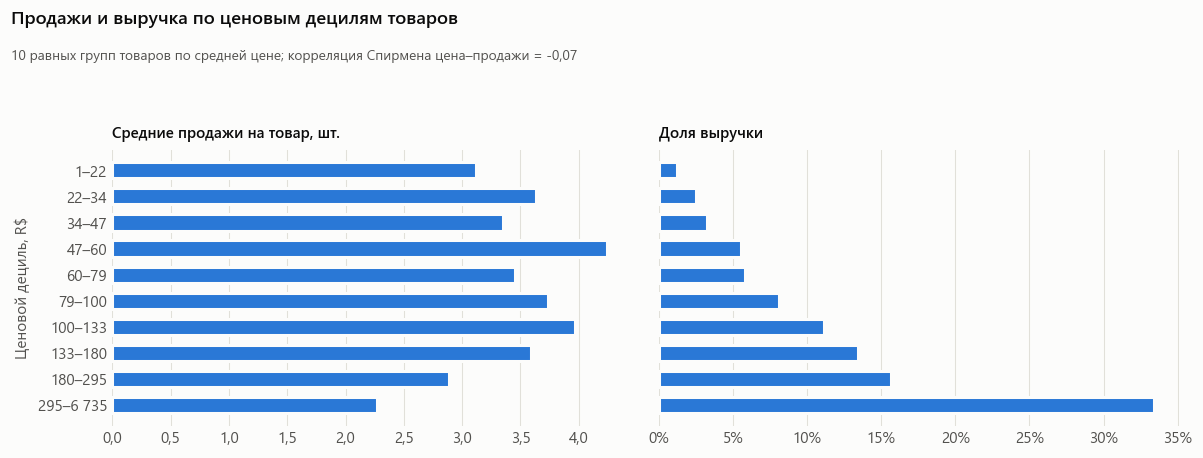

In [8]:
labels = [f"{st.num(a)}–{st.num(b)}" for a, b in zip(deciles.price_from, deciles.price_to)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
axes[0].barh(labels[::-1], deciles.avg_units[::-1], color=st.BLUE, height=0.62, edgecolor=st.SURFACE, linewidth=2)
axes[0].set_title("Средние продажи на товар, шт.", loc="left", fontsize=10, pad=8)
axes[1].barh(labels[::-1], deciles.revenue_share[::-1], color=st.BLUE, height=0.62, edgecolor=st.SURFACE, linewidth=2)
axes[1].set_title("Доля выручки", loc="left", fontsize=10, pad=8)
st.percent_axis(axes[1], "x")
for a in axes:
    a.grid(axis="y", visible=False)
    a.grid(axis="x", visible=True)
    a.spines["bottom"].set_visible(False)
axes[0].set_ylabel("Ценовой дециль, R$")
fig.suptitle("Продажи и выручка по ценовым децилям товаров", x=0.01, ha="left", fontsize=12, fontweight="semibold")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: st.num(v, 1)))
fig.text(0.01, 0.875, f"10 равных групп товаров по средней цене; корреляция Спирмена цена–продажи = {st.num(spearman, 2)}",
         fontsize=9, color=st.INK_2)
fig.tight_layout(rect=(0, 0, 1, 0.84))
st.save(fig, "olist_products_03_price_deciles")
plt.show()

**Формула** (ранговая корреляция Спирмена)

$$\rho = 1 - \frac{6\sum_{i=1}^{n} d_i^2}{n(n^2 - 1)}$$

где $d_i$ — разность рангов товара $i$ по цене и по продажам, $n$ — число товаров.
При совпадающих значениях (у 55% товаров продажи равны 1) $\rho$ считается как корреляция Пирсона между рангами.
Спирмен устойчив к выбросам и ловит любую монотонную связь, а не только линейную.

**Пример расчёта**

$$n = 32\,729, \qquad \rho \approx -0{,}07, \qquad \rho^2 \approx 0{,}005$$

Ранг цены объясняет меньше 1% разброса рангов продаж.

**Вывод.**
- **Связи между ценой и продажами почти нет**: корреляция Спирмена −0,07. В каждом ценовом дециле товар
  продаётся в среднем 3–4 раза; только в самом дорогом дециле (от ~R&#36; 295) — 2,3 раза.
- При этом выручка сильно смещена к дорогим товарам: **верхний дециль цены даёт треть выручки (33%)**,
  нижний — 1%.
- Вывод для ассортимента: дорогие товары почти не теряют в частоте продаж, поэтому расширение ассортимента
  в дорогом сегменте даёт заметно больше выручки на товар, чем в дешёвом.
- Это сравнение между разными товарами; оно не показывает, как изменятся продажи одного товара при изменении
  его цены (для этого нужны данные об изменениях цен).

## Доля категорий в общей выручке и её изменение

**Вопрос:** как распределена выручка по категориям и какие категории набирают вес?
**Метрика:** доля категории в выручке за январь–август 2017 и январь–август 2018 (одинаковые месяцы, чтобы сезонность не искажала сравнение).
Общая структура выручки за весь период — в ноутбуке продаж, раздел «Категории с наибольшей выручкой».

In [9]:
shares = q("""
    select p.category_en, d.year, sum(i.price) as revenue
    from fact_order_items i
    join dim_product p using (product_key)
    join dim_date d on d.date_key = i.purchase_date_key
    where i.is_valid_order and d.month between 1 and 8 and d.year in (2017, 2018)
    group by 1, 2
""").pivot(index="category_en", columns="year", values="revenue").fillna(0)
shares = shares / shares.sum()
shares.columns = ["share_2017", "share_2018"]
shares["change_pp"] = (shares.share_2018 - shares.share_2017) * 100
top = shares.sort_values("share_2018", ascending=False).head(15)
view = st.as_pct(top.reset_index(), ["share_2017", "share_2018"])
view["change_pp"] = top.change_pp.map(lambda v: f"{v:+.1f}".replace(".", ",") + " п.п.").values
view

,category_en,share_2017,share_2018,change_pp
0,health_beauty,"8,0%","10,5%","+2,5 п.п."
1,watches_gifts,"6,7%","9,6%","+3,0 п.п."
2,bed_bath_table,"8,4%","7,3%","-1,1 п.п."
3,sports_leisure,"7,3%","7,2%","-0,1 п.п."
4,computers_accessories,"7,1%","6,8%","-0,3 п.п."
5,housewares,"4,3%","5,4%","+1,2 п.п."
6,furniture_decor,"5,9%","5,2%","-0,6 п.п."
7,auto,"4,2%","4,7%","+0,6 п.п."
8,baby,"2,3%","3,5%","+1,2 п.п."
9,cool_stuff,"6,9%","3,1%","-3,7 п.п."


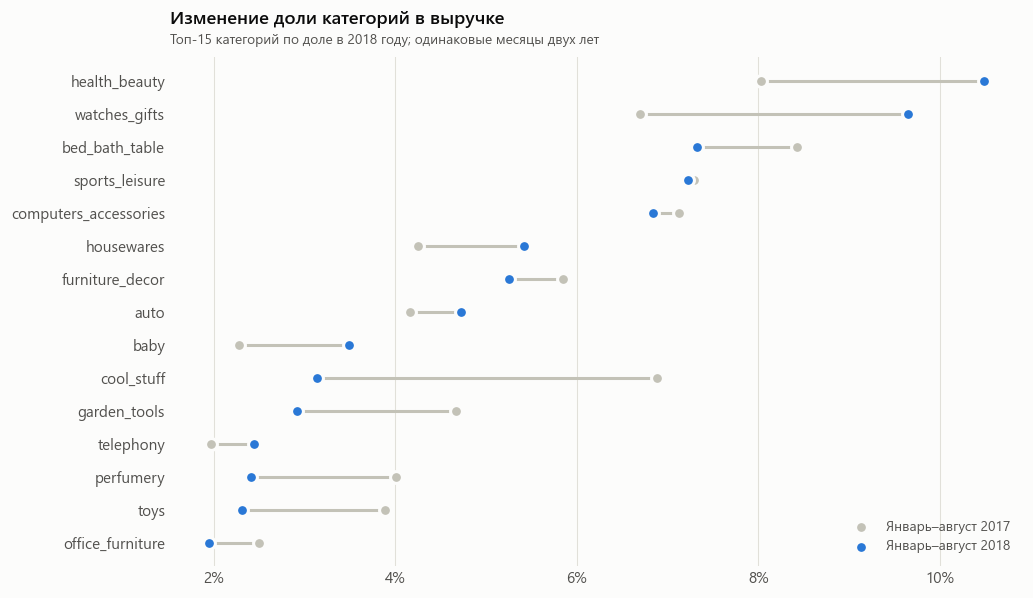

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
order = top.iloc[::-1]
y = np.arange(len(order))
ax.hlines(y, order.share_2017, order.share_2018, color=st.AXIS, linewidth=2, zorder=1)
ax.scatter(order.share_2017, y, s=60, color=st.CONTEXT, edgecolor=st.SURFACE, linewidth=2, zorder=3, label="Январь–август 2017")
ax.scatter(order.share_2018, y, s=60, color=st.BLUE, edgecolor=st.SURFACE, linewidth=2, zorder=3, label="Январь–август 2018")
ax.set_yticks(y, order.index)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.spines["bottom"].set_visible(False)
st.percent_axis(ax, "x")
ax.legend(loc="lower right")
st.titles(ax, "Изменение доли категорий в выручке", "Топ-15 категорий по доле в 2018 году; одинаковые месяцы двух лет")
st.save(fig, "olist_products_04_category_share_change")
plt.show()

In [11]:
changes = shares[(shares.share_2017 > 0.005) | (shares.share_2018 > 0.005)].sort_values("change_pp")
pd.concat([changes.head(5), changes.tail(5)])[["change_pp"]].rename(columns={"change_pp": "изменение, п.п."})

,"изменение, п.п."
category_en,
cool_stuff,"-3,74"
garden_tools,"-1,74"
perfumery,"-1,60"
toys,"-1,57"
bed_bath_table,"-1,10"
housewares,"1,16"
baby,"1,21"
construction_tools_construction,"1,58"
health_beauty,"2,46"


**Формула**

$$\Delta_k = 100 \cdot \left(s^{2018}_k - s^{2017}_k\right), \qquad s^{y}_k = \frac{R^{y}_k}{R^{y}}$$

где $R^{y}_k$ — выручка категории $k$ за январь–август года $y$, $R^{y}$ — вся выручка за те же месяцы,
$\Delta_k$ — изменение доли в процентных пунктах.

**Пример расчёта** (health_beauty)

$$s^{2018} = \frac{770\,002{,}81}{7\,341\,037{,}41} \approx 0{,}1049, \qquad s^{2017} = \frac{247\,457{,}95}{3\,080\,850{,}81} \approx 0{,}0803$$

$$\Delta = 100 \cdot (0{,}1049 - 0{,}0803) \approx +2{,}46 \text{ п.п.}$$

**Вывод.**
- Структура выручки стала **концентрированнее вокруг двух лидеров**: health_beauty (+2,5 п.п., до 10,5%) и
  watches_gifts (+3,0 п.п., до 9,6%) выросли быстрее рынка.
- Также выросли housewares и baby (+1,2 п.п.), а construction_tools_construction — с 0,1% до 1,7% (новая для площадки категория).
- **Больше всех потеряла cool_stuff**: доля упала вдвое, с 6,9% до 3,1%. Сократились garden_tools,
  perfumery, toys (−1,5…−1,7 п.п.) и bed_bath_table (−1,1 п.п.).
- Потеря доли не обязательно означает падение продаж: вся выручка выросла в 2,4 раза, и категории
  с отрицательным изменением доли в основном росли медленнее рынка.

## Товары с высокой выручкой при малом числе заказов

**Вопрос:** есть ли товары, которые приносят много выручки при единичных заказах, и что это за товары?
**Метрика:** товары из верхних 10% по выручке, у которых не больше трёх заказов.

In [12]:
p90 = products.revenue.quantile(0.9)
niche = products[(products.revenue >= p90) & (products.orders <= 3)]
summary = pd.DataFrame({
    "порог выручки (90-й перцентиль), R$": [p90],
    "нишевых товаров": [len(niche)],
    "доля товаров": [st.pct(len(niche) / len(products), 1)],
    "доля выручки": [st.pct(niche.revenue.sum() / products.revenue.sum(), 1)],
    "медианная цена, R$": [niche.avg_price.median()],
    "средняя оценка": [niche.avg_review_score.mean()],
    "средняя оценка всех товаров": [products.avg_review_score.mean()],
})
summary.T.set_axis(["значение"], axis=1)

,значение
"порог выручки (90-й перцентиль), R$","801,36"
нишевых товаров,1107
доля товаров,"3,4%"
доля выручки,"12,9%"
"медианная цена, R$","859,99"
средняя оценка,"4,02"
средняя оценка всех товаров,"4,07"


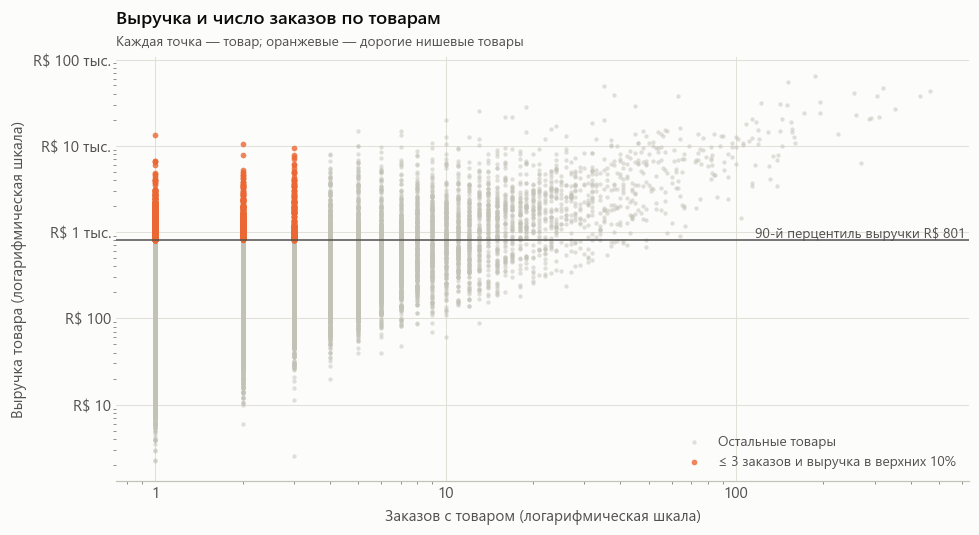

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
rest = products.drop(niche.index)
ax.scatter(rest.orders, rest.revenue, s=8, color=st.CONTEXT, alpha=0.5, linewidth=0, label="Остальные товары")
ax.scatter(niche.orders, niche.revenue, s=14, color=st.ORANGE, alpha=0.8, linewidth=0, label="≤ 3 заказов и выручка в верхних 10%")
ax.set_xscale("log")
ax.set_yscale("log")
ax.axhline(p90, color=st.INK_2, linewidth=1)
ax.text(ax.get_xlim()[1], p90, f"90-й перцентиль выручки {st.money(p90)} ", ha="right", va="bottom", fontsize=9, color=st.INK_2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: st.num(v)))
st.money_axis(ax, "y")
ax.grid(axis="x", visible=True)
ax.set_xlabel("Заказов с товаром (логарифмическая шкала)")
ax.set_ylabel("Выручка товара (логарифмическая шкала)")
ax.legend(loc="lower right")
st.titles(ax, "Выручка и число заказов по товарам", "Каждая точка — товар; оранжевые — дорогие нишевые товары")
st.save(fig, "olist_products_05_niche_products")
plt.show()

In [14]:
by_cat = (niche.groupby("category_en")
          .agg(products=("product_key", "size"), revenue=("revenue", "sum"), median_price=("avg_price", "median"))
          .sort_values("revenue", ascending=False))
by_cat.head(10)

,products,revenue,median_price
category_en,,,
watches_gifts,158,"237 210,30","999,94"
sports_leisure,81,"130 829,29","836,99"
health_beauty,74,"111 456,03","899,05"
computers_accessories,59,"104 461,79","945,00"
auto,67,"104 242,55","736,67"
garden_tools,58,"102 817,28","979,50"
cool_stuff,56,"74 014,39","750,65"
small_appliances,29,"68 539,39","999,90"
baby,45,"68 025,43","890,00"


**Формула**

$$P_{90} = x_{(\lfloor h \rfloor)} + (h - \lfloor h \rfloor)\left(x_{(\lfloor h \rfloor + 1)} - x_{(\lfloor h \rfloor)}\right), \qquad h = 0{,}9\,(J - 1) + 1$$

$$\mathcal{N} = \{\, j : R_j \ge P_{90},\ O_j \le 3 \,\}$$

где $x_{(m)}$ — выручки товаров по возрастанию, $P_{90}$ — 90-й перцентиль с линейной интерполяцией,
$O_j$ — число заказов с товаром $j$, $\mathcal{N}$ — дорогие нишевые товары.

**Пример расчёта**

$$P_{90} \approx 801{,}36, \qquad |\mathcal{N}| = 1\,107, \qquad \frac{1\,107}{32\,729} \approx 0{,}034, \qquad \frac{1\,739\,436{,}15}{13\,494\,400{,}74} \approx 0{,}129$$

**Вывод.**
- **1 107 товаров (3,4% ассортимента) при одном–трёх заказах дают 12,9% выручки** — почти столько же,
  сколько топ-100 бестселлеров.
- Это дорогие товары: медианная цена **R&#36; 860** против R&#36; 87 у типичного заказа. Больше всего их в
  watches_gifts (часы), sports_leisure, health_beauty, computers_accessories, auto, garden_tools и small_appliances.
- Оценки у них на уровне остальных товаров (около 4,0), то есть дорогие разовые покупки не приводят к
  большему недовольству.
- Для площадки это важный сегмент: каждый такой товар продаётся редко, но вместе они дают заметную долю выручки.
  Их видимость в поиске и наличие у продавцов влияют на выручку сильнее, чем можно судить по числу заказов.

## Итоги

| Вопрос | Ответ |
|---|---|
| Самые продаваемые товары | длинный хвост: 55% товаров проданы один раз; топ-100 дают 13,5% выручки; лидеры — недорогие товары для дома и сада |
| Цена и продажи | связи почти нет (Спирмен −0,07); верхний ценовой дециль — 33% выручки |
| Доли категорий | health_beauty и watches_gifts выросли до ~10% каждая; cool_stuff потеряла половину доли |
| Высокая выручка при малом числе заказов | 1 107 дорогих товаров (медиана R&#36; 860) с ≤ 3 заказами — 12,9% выручки |